In [1]:
import itertools
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from IPython.display import display
from scipy.optimize import linprog

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 20)
pd.set_option("display.precision", 2)

# ДЗ 2. Лінійні оптимізаційні моделі у наскрізному ІТ-кейсі

Варіант 1 -- хмарний API

Виконав: Олег Басистий

## 1. Опис системи

Хмарний API обслуговується з двох майданчиків, $S_1$ (Cloud East) і $S_2$ (Cloud West). Попит надходить від трьох груп клієнтів, $D_1$ -- корпоративні клієнти, $D_2$ -- мобільні клієнти, $D_3$ -- партнерські API. Одиниця потоку -- пакет API-запитів.

Рішення приймається у два етапи:

- Етап A. Скільки агрегованих одиниць сервісної потужності активувати на S1 і S2, щоб отримати найбільший сумарний технічний ефект за даних обмежень.
- Етап B. Як розподілити відомий попит D1-D3 між майданчиками з мінімальною сумарною вартістю, не перевищуючи активованої на етапі A потужності.

Результат A це вектор $x^*$, який передається в B як верхні межі потоку з кожного майданчика, можлива невикористана потужність.

Стейкхолдер: власник ІТ-системи (платформна команда), який вирішує, яку потужність резервувати, і відповідає за вартість обслуговування клієнтів.

## 2. Прогноз до запуску solver

*Записано до обчислень, після запуску не редагувався.*

1. Дефіцитний ресурс -- CPU-години. S1 витрачає 4 CPU-год на одиницю потужності і водночас дає більший ефект, тому оптимізація нарощуватиме S1, доки не вичерпає CPU.
2. Обидва обмеження є активними. Ефект на CPU-годину: S1 -- 9/4 = 2,25, S2 -- 7/2 = 3,5; на RAM-годину: S1 -- 9, S2 -- 7/3 ~ 2,3. Майданчики 'дешеві' за різними ресурсами, тому очікується змішаний план $x_1^*, x_2^* > 0$ у вершині, де активні і CPU, і RAM.
3. Привабливі маршрути: S1 -> D1 (4), S2 -> D2 (4) і S1 -> D3 (6) од./пакет; S1 -> D2 і S2 -> D3 (по 9) використовуватимуться лише вимушено.
4. Сумарна потужність, ймовірно, перевищить попит 13 + 16 + 16 = 45 пакетів, і частина її лишиться вільною.  S1 може не вистачити на обидва напрями D1 + D3 = 29 пакетів, і частину доведеться віддати дорожчому S2.
5. Скорочення CPU найбільше вдарить по S1, а заборона S1 -> D3 змусить обслуговувати весь D3 з S2 за 9, тому $C^*$ помітно зросте.

## 3. Паспорт і формальна модель A

### Операційні рішення

- Модель A: скільки агрегованих одиниць потужності $x_1, x_2$ активувати на S1 і S2 на плановий період. $x_i^*$ -- це доступна межа обслуговування.
- Модель B: скільки пакетів $y_{ij}$ спрямувати з майданчика $S_i$ до напряму $D_j$, щоб повністю задовольнити попит з мінімальною вартістю в межах $x^*$.

### Паспорт моделей

| Елемент | Позначення | Зміст | Одиниці | Джерело |
|---|---|---|---|---|
| Керовані змінні A | $x_1, x_2$ | потужність, активована на S1, S2; неперервні, $x_i \ge 0$ | од. потужності (1 од. = здатність обслужити 1 пакет за період) | рішення власника системи |
| Керовані змінні B | $y_{ij}$, $i = 1, 2$, $j = 1, 2, 3$ | потік з $S_i$ до $D_j$, $y_{ij} \ge 0$ | пакети API-запитів | рішення маршрутизації |
| Параметри $a$ | $a_{ri}$ | споживання ресурсу $r$ однією одиницею потужності на $S_i$ | CPU-год/од., RAM-год/од. | таблиця варіанта (синтетичні); у реальній системі -- профілювання |
| | $b_r$ | запас ресурсу: $b_{CPU} = 164$, $b_{RAM} = 111$ | CPU-год, RAM-год | таблиця варіанта; у реальності -- квоти, бюджет |
| | $p_i$ | технічний ефект однієї одиниці потужності: $p = (9, 7)$ | од. ефекту / од. | таблиця варіанта; у реальності -- експертна оцінка |
| | $c_{ij}$ | питома вартість обслуговування пакета з $S_i$ для $D_j$ | грош. од./пакет | таблиця варіанта; у реальності -- тарифи трафіку, SLA |
| | $d_j$ | попит напряму: $d = (13, 16, 16)$ | пакети | таблиця варіанта; у реальності -- прогноз попиту |
| Сценарні фактори $\xi$ | $\xi_1$ | масштаб запасу CPU: $b_{CPU} \to \xi_1 b_{CPU}$, $\xi_1 \in [0{,}85;\ 1{,}15]$ | частка від бази | сценарій варіанта |
| | $\xi_2$ | доступність маршруту S1->D3 (так / ні) | -- | стрес-сценарій |
| Критерій A | $W$ | сумарний технічний ефект, **max** | од. ефекту | -- |
| Критерій B | $C$ | сумарна вартість обслуговування, **min** | грош. од. | -- |

Запас RAM, коефіцієнти $a_{ri}, p_i, c_{ij}$ і попит $d_j$ у всіх сценаріях однакові, попит лишається базовим навіть у стресі. Змінюємо лише запас CPU ($\xi_1$), а маршрут S1->D3 ($\xi_2$) закриваємо тільки в стрес-точці 85 %.

Допустимі плани моделі A утворюють множину $X = \{x \ge 0 : Ax \le b\}$, а допустимі потоки моделі B -- множину $Y(x^*) = \{y \ge 0 : \sum_j y_{ij} \le x_i^*,\ \sum_i y_{ij} = d_j\}$. У стресі до неї додається умова $y_{13} = 0$.

Потужність $x_i$ і потік $y_{ij}$ рахуємо в тих самих одиницях, у пакетах за період, тому в обмеженні $\sum_j y_{ij} \le x_i^*$ не потрібні коефіцієнти переведення.

### Формальна модель A

$$\max_{x}\; W(x) = 9x_1 + 7x_2 \quad \text{[од. ефекту]}$$

за обмежень

$$
\begin{aligned}
4x_1 + 2x_2 &\le 164 &&\text{CPU-год}\\
x_1 + 3x_2 &\le 111 &&\text{RAM-год}\\
x_1,\ x_2 &\ge 0.
\end{aligned}
$$

$X$ -- опуклий багатокутник, тому оптимум досягається в одній з його вершин.

`linprog` лише мінімізує, тому задачу максимізації переписуємо як $\min\,(-W) = -9x_1 - 7x_2$, тобто `c = [-9, -7]`. `A_ub` -- матриця споживання ресурсів, `b_ub` -- запаси, `bounds = [(0, None)] * 2`. Оптимальне значення цілі тоді дорівнює `-res.fun`.

In [2]:
SITES = ["S1", "S2"]
DESTS = ["D1", "D2", "D3"]
RESOURCES = ["CPU", "RAM"]

# Model A
RES_USE = np.array([[4, 2],          # CPU-hours
                    [1, 3]], float)  # RAM-hours
RES_STOCK = np.array([164, 111], float)  # available CPU-hours, RAM-hours
EFFECT = np.array([9, 7], float)

# Model B
COST = np.array([[4, 9, 6],          # cost per packet S1 -> D1, D2, D3
                 [7, 4, 9]], float)  # cost per packet S2 -> D1, D2, D3
DEMAND = np.array([13, 16, 16], float)   # packets

# Stress scenario and sensitivity analysis
STRESS_RES = RESOURCES.index("CPU")
STRESS_FACTOR = 0.85
STRESS_BANNED = frozenset({(0, 2)})  # route S1 -> D3 is unavailable
SWEEP_FACTORS = np.round(np.arange(0.85, 1.15 + 1e-9, 0.05), 2)

TOL = 1e-6

N_SITES, N_DESTS = COST.shape

In [3]:
def route(i, j):
    return f"{SITES[i]}->{DESTS[j]}"


def scaled_stock(factor, res=STRESS_RES):
    """
    Copy of the base resource stock with one resource scaled by factor.
    """
    stock = RES_STOCK.copy()
    stock[res] *= factor
    return stock

In [4]:
display(pd.DataFrame(np.column_stack([RES_USE, RES_STOCK]),
                     index=["CPU-hours", "RAM-hours"], columns=["S1", "S2", "stock"]))
display(pd.DataFrame(np.vstack([COST, DEMAND]), index=["S1", "S2", "demand"], columns=DESTS))

,S1,S2,stock
CPU-hours,4.0,2.0,164.0
RAM-hours,1.0,3.0,111.0


,D1,D2,D3
S1,4.0,9.0,6.0
S2,7.0,4.0,9.0
demand,13.0,16.0,16.0


## 4. Модель A: код, результат і перевірка

In [5]:
def build_model_a(res_stock=RES_STOCK):
    """
    Build the arrays for model A in linprog form: 
    max W = p @ x  ->  min (-p) @ x.
    """
    return dict(c=-EFFECT,
                A_ub=RES_USE,
                b_ub=np.asarray(res_stock, float),
                bounds=[(0, None)] * len(EFFECT))


def solve_model_a(res_stock=RES_STOCK):
    return linprog(**build_model_a(res_stock), method="highs")

In [6]:
def resource_table(res_a, res_stock=RES_STOCK):
    """
    Create a table of resource usage and slack for a solved model A."""
    used = RES_USE @ res_a.x
    slack = res_stock - used
    return pd.DataFrame({
        "used": used,
        "stock": res_stock,
        "slack": slack,
        "active": slack <= TOL,
    }, index=RESOURCES)

In [7]:
for name, value in build_model_a().items():
    print(f"{name:6s} = {value.tolist() if isinstance(value, np.ndarray) else value}")

c      = [-9.0, -7.0]
A_ub   = [[4.0, 2.0], [1.0, 3.0]]
b_ub   = [164.0, 111.0]
bounds = [(0, None), (0, None)]


In [8]:
res_a = solve_model_a()
print(f"status: {res_a.status} ({res_a.message})")
assert res_a.status == 0, "model A is not solved"

W_star = -res_a.fun
print(f"x* = {res_a.x.round(4)} capacity units (S1, S2)")
print(f"W* = {W_star:.4f} effect units")
display(resource_table(res_a))

status: 0 (Optimization terminated successfully. (HiGHS Status 7: Optimal))
x* = [27. 28.] capacity units (S1, S2)
W* = 439.0000 effect units


,used,stock,slack,active
CPU,164.0,164.0,0.0,True
RAM,111.0,111.0,0.0,True


Solver повернув статус 0, тобто оптимум знайдено, і дав $x^* = (27;\ 28)$, $W^* = 439$. Обидва ресурси вичерпано повністю, тож обидва обмеження активні, і оптимум лежить у вершині їх перетину.

Оскільки обидва ресурси вичерпано, зміна запасу будь-якого з них зсуне оптимум. Як саме $W^*$ реагує на запас CPU, перевіримо в розділі 8.

### Перевірка вручну

Обидва обмеження активні, тому розв'язуємо систему $4x_1 + 2x_2 = 164$, $x_1 + 3x_2 = 111$. З другого рівняння $x_1 = 111 - 3x_2$, і після підстановки в перше отримуємо $444 - 12x_2 + 2x_2 = 164 \Rightarrow x_2 = 28$, $x_1 = 27$. $W = 9 \cdot 27 + 7 \cdot 28 = 243 + 196 = 439$.

В інших вершинах $X$ ефект менший, а саме $(0;\ 0)$ -- $W = 0$; $(41;\ 0)$ (CPU вичерпано, RAM $41 \le 111$) -- $W = 369$; $(0;\ 37)$ (RAM вичерпано, CPU $74 \le 164$) -- $W = 259$. Максимум -- у вершині $(27;\ 28)$.

In [9]:
manual_a = {"x1": 27, "x2": 28, "W": 439}
model_a_values = {"x1": res_a.x[0], "x2": res_a.x[1], "W": W_star}
for k, v in manual_a.items():
    print(f"{k:11s} by hand = {v:4}, linprog = {model_a_values[k]:9.4f}, match: {np.isclose(v, model_a_values[k])}")
    assert np.isclose(v, model_a_values[k])

x1          by hand =   27, linprog =   27.0000, match: True
x2          by hand =   28, linprog =   28.0000, match: True
W           by hand =  439, linprog =  439.0000, match: True


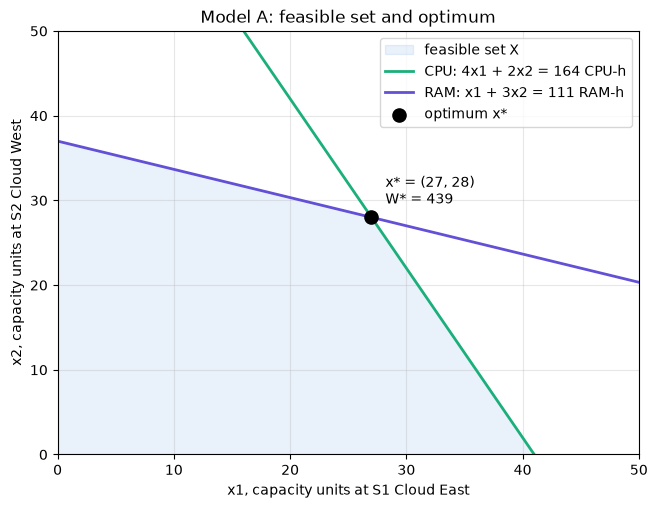

In [10]:
CPU_COLOR, RAM_COLOR = "#1baf7a", "#6250d6"
S1_COLOR, S2_COLOR = "#2a78d6", "#eb6834"
INK = "#52514e"
STRESS_COLOR = "#e34948"

x1_grid = np.linspace(0, 50, 401)
# x2 on the boundary of each resource constraint: a_r1 x1 + a_r2 x2 = b_r
boundaries = (RES_STOCK[:, None] - RES_USE[:, [0]] * x1_grid) / RES_USE[:, [1]]

fig, ax = plt.subplots(figsize=(7.5, 5.5))
ax.fill_between(x1_grid, 0, np.clip(boundaries.min(axis=0), 0, None),
                color=S1_COLOR, alpha=0.10, label="feasible set X")
ax.plot(x1_grid, boundaries[0], color=CPU_COLOR, lw=2, label="CPU: 4x1 + 2x2 = 164 CPU-h")
ax.plot(x1_grid, boundaries[1], color=RAM_COLOR, lw=2, label="RAM: x1 + 3x2 = 111 RAM-h")
ax.scatter(*res_a.x, s=90, color="black", zorder=4, label="optimum x*")
ax.annotate(f"x* = ({res_a.x[0]:.0f}, {res_a.x[1]:.0f})\nW* = {W_star:.0f}", res_a.x,
            textcoords="offset points", xytext=(10, 10))

ax.set_xlim(0, 50)
ax.set_ylim(0, 50)
ax.set_xlabel("x1, capacity units at S1 Cloud East")
ax.set_ylabel("x2, capacity units at S2 Cloud West")
ax.set_title("Model A: feasible set and optimum")
ax.grid(alpha=0.3)
ax.legend()
plt.show()

## 5. Формальна модель B і передавання $x^*$

$$\min_{y}\; C(y) = \sum_{i=1}^{2}\sum_{j=1}^{3} c_{ij}\, y_{ij} = 4y_{11} + 9y_{12} + 6y_{13} + 7y_{21} + 4y_{22} + 9y_{23} \quad \text{[грош. од.]}$$

за обмежень

$$
\begin{aligned}
\sum_{j} y_{ij} &\le x_i^*, && i = 1, 2 &&\text{(потужність, пакети)}\\
\sum_{i} y_{ij} &= d_j, && j = 1, 2, 3 &&\text{(попит, пакети)}\\
y_{ij} &\ge 0; && \text{у стресі ще } y_{13} = 0 &&\text{(маршрут S1->D3 заборонено).}
\end{aligned}
$$

Для `linprog` змінні зібрано у вектор $y = (y_{11}, y_{12}, y_{13}, y_{21}, y_{22}, y_{23})$. Заборону маршруту задаємо межею `bounds = (0, 0)` для відповідної змінної, тож матриці обмежень не змінюються.

Потужності $x^*$ модель B бере прямо з об'єкта результату `res_a.x`, без ручного копіювання чисел, і `capacity = res_a.x` стає правою частиною обмежень потужності `b_ub`.

In [11]:
def build_model_b(capacity, banned=frozenset(), cost=COST, demand=DEMAND):
    """
    Builds arrays for model B:
    min sum c_ij y_ij, capacity (<=), demand (=), banned routes fixed at 0.
    """
    n_s, n_d = cost.shape
    c = cost.ravel()                                # y = [y11, y12, y13, y21, y22, y23]
    A_ub = np.zeros((n_s, n_s * n_d))               # sum_j y_ij <= x_i*
    for i in range(n_s):
        A_ub[i, i * n_d:(i + 1) * n_d] = 1
    A_eq = np.zeros((n_d, n_s * n_d))               # sum_i y_ij = d_j
    for j in range(n_d):
        A_eq[j, j::n_d] = 1
    bounds = [(0, 0) if (i, j) in banned else (0, None)
              for i in range(n_s) for j in range(n_d)]
    return dict(c=c, A_ub=A_ub, b_ub=np.asarray(capacity, float),
                A_eq=A_eq, b_eq=np.asarray(demand, float), bounds=bounds)

def solve_model_b(capacity, banned=frozenset(), cost=COST, demand=DEMAND):
    return linprog(**build_model_b(capacity, banned, cost, demand), method="highs")

In [12]:
capacity = res_a.x.copy() 
model_b = build_model_b(capacity)
print("c    =", model_b["c"])
print("A_ub =\n", model_b["A_ub"], "\nb_ub =", model_b["b_ub"].round(4))
print("A_eq =\n", model_b["A_eq"], "\nb_eq =", model_b["b_eq"])
print(f"total capacity = {capacity.sum():.2f} packets, total demand = {DEMAND.sum():.0f} packets")

c    = [4. 9. 6. 7. 4. 9.]
A_ub =
 [[1. 1. 1. 0. 0. 0.]
 [0. 0. 0. 1. 1. 1.]] 
b_ub = [27. 28.]
A_eq =
 [[1. 0. 0. 1. 0. 0.]
 [0. 1. 0. 0. 1. 0.]
 [0. 0. 1. 0. 0. 1.]] 
b_eq = [13. 16. 16.]
total capacity = 55.00 packets, total demand = 45 packets


### Завдання на виявлення помилки. Чому не $\sum_j y_{ij} = x_i^*$

Рівність означала б, що кожен майданчик зобов'язаний відправити весь активований обсяг. Але $x_i^*$ -- це межа, до якої майданчик може обслуговувати, а не план відправлення.

У нашому варіанті $x_1^* + x_2^* = 27 + 28 = 55$ одиниць, а сумарний попит $13 + 16 + 16 = 45$ пакетів. Якщо виконано обидві рівності потужності, то $\sum_{i,j} y_{ij} = 55$, а рівності попиту дають $\sum_{i,j} y_{ij} = 45$. Це суперечність, і задача недопустима. Фізично це означало б «доставити» клієнтам 10 пакетів, яких ніхто не замовляв. Перевіримо це solver-ом.

In [13]:
# Wrong model, capacity as equality, sum_j y_ij = x_i*
wrong = build_model_b(capacity)
res_wrong = linprog(wrong["c"],
                    A_eq=np.vstack([wrong["A_ub"], wrong["A_eq"]]),
                    b_eq=np.concatenate([wrong["b_ub"], wrong["b_eq"]]),
                    bounds=wrong["bounds"], method="highs")
print(f"equality version: status {res_wrong.status} - {res_wrong.message}")
print(f"sum of x* = {capacity.sum():.2f} != sum of demand = {DEMAND.sum():.0f}")

equality version: status 2 - The problem is infeasible. (HiGHS Status 8: model_status is Infeasible; primal_status is None)
sum of x* = 55.00 != sum of demand = 45


Статус 2 означає, що задача недопустима. З правильною нерівністю ті самі дані дають допустимий план, у якому 10 одиниць потужності S2 лишаються вільними (розділ 6).

## 6. Модель B: код, результат і перевірка

In [14]:
def flow_table(y, capacity):
    """
    Flow matrix with site usage, spare capacity and demand check.
    """
    y = np.asarray(y, float).reshape(N_SITES, N_DESTS)
    cap = np.asarray(capacity, float)
    t = pd.DataFrame(y, index=SITES, columns=DESTS)
    t["used"] = y.sum(axis=1)
    t["capacity x*"] = cap
    t["spare"] = cap - y.sum(axis=1)
    t["utilization, %"] = 100 * y.sum(axis=1) / cap
    t.loc["served"] = [*y.sum(axis=0), y.sum(), cap.sum(), cap.sum() - y.sum(), 100 * y.sum() / cap.sum()]
    t = t.round(2).astype(object)
    t.loc["demand"] = [*DEMAND, DEMAND.sum(), "", "", ""]
    return t

In [15]:
res_b = solve_model_b(capacity)
print(f"status: {res_b.status} ({res_b.message})")
assert res_b.status == 0, "model B is not solved"

C_star = res_b.fun
Y_star = res_b.x.reshape(N_SITES, N_DESTS)
print(f"C* = {C_star:.4f} cost units")
display(flow_table(Y_star, capacity))

status: 0 (Optimization terminated successfully. (HiGHS Status 7: Optimal))
C* = 218.0000 cost units


,D1,D2,D3,used,capacity x*,spare,"utilization, %"
S1,13.0,0.0,14.0,27.0,27.0,0.0,100.0
S2,0.0,16.0,2.0,18.0,28.0,10.0,64.29
served,13.0,16.0,16.0,45.0,55.0,10.0,81.82
demand,13.0,16.0,16.0,45.0,,,


$C^* = 218$. Потік іде переважно найдешевшими маршрутами S1->D1 (13), S2->D2 (16) і S1->D3 (14). S1 завантажено на 100 %, і саме його потужність обмежує план, тому 2 пакети D3 доводиться обслуговувати з S2 за 9 замість 6 (+3 за пакет). S2 використовує 18 з 28 одиниць, тож 10 одиниць лишаються невикористаним резервом. Прогноз, що S1 не вистачить на D1 + D3 = 29 > 27 пакетів, підтвердився.

### Перевірка вручну

Без обмеження потужності кожен напрям ішов би найдешевшим маршрутом, і вартість була б $4 \cdot 13 + 4 \cdot 16 + 6 \cdot 16 = 212$, але S1 тоді потрібно 29 > 27 одиниць. Два «зайві» пакети переносимо на S2 з найменшою доплатою, і це може бути D1 ($7 - 4 = 3$) або D3 ($9 - 6 = 3$). $C = 212 + 2 \cdot 3 = 218$.

In [16]:
assert np.isclose(C_star, 218)

Y_alt = np.array([[11, 0, 16],
                  [2, 16, 0]], float)
print(f"alternative plan cost = {(COST * Y_alt).sum():.2f}, LP optimum C* = {C_star:.2f}")
assert np.isclose((COST * Y_alt).sum(), C_star)

alternative plan cost = 218.00, LP optimum C* = 218.00


Оптимум B не єдиний, бо перенести на S2 частину D1 замість D3 коштує ті самі +3 за пакет. Наприклад, план S1: D1 = 11, D3 = 16; S2: D1 = 2, D2 = 16 теж дає $4 \cdot 11 + 6 \cdot 16 + 7 \cdot 2 + 4 \cdot 16 = 218$. Solver повернув одну з рівноцінних вершин. Для власника системи це означає, що вибір, кого з D1 чи D3 частково обслуговувати з Cloud West, можна зробити за іншим критерієм (наприклад, SLA корпоративних клієнтів) без втрат у вартості.

## 7. Жадібний базовий алгоритм і порівняння

За жадібним правилом впорядковуємо дозволені пари $(S_i, D_j)$ за зростанням $c_{ij}$ (при рівності -- за номером майданчика, потім напряму) і кожній парі віддаємо $\min(\text{залишок потужності } S_i,\ \text{залишок попиту } D_j)$.

Після завершення програмно перевіряємо рівності попиту, обмеження потужності, невід'ємність і заборони маршрутів. Вартість порівнюємо з оптимумом лише для допустимого плану.

In [17]:
def greedy_flow(capacity, banned=frozenset(), cost=COST, demand=DEMAND, single_source_first=False):
    """
    Greedy rule
    Fill allowed routes in ascending cost order.

    single_source_first=True is the repaired variant, destinations that have only
    one allowed source are served before the others.
    """
    n_s, n_d = cost.shape
    cap_left = np.array(capacity, float)
    dem_left = np.array(demand, float)
    y = np.zeros((n_s, n_d))
    n_sources = [sum((i, j) not in banned for i in range(n_s)) for j in range(n_d)]
    pairs = [(i, j) for i in range(n_s) for j in range(n_d) if (i, j) not in banned]
    if single_source_first:
        order = sorted(pairs, key=lambda p: (n_sources[p[1]], cost[p], p))
    else:
        order = sorted(pairs, key=lambda p: (cost[p], p))

    steps = []
    for i, j in order:
        q = min(cap_left[i], dem_left[j])
        q = q if q > TOL else 0.0
        y[i, j] = q
        cap_left[i] -= q
        dem_left[j] -= q
        steps.append({"route": f"S{i + 1}->D{j + 1}", "cost": cost[i, j], "sent": q,
                      "site cap left": cap_left[i], "demand left": dem_left[j]})
    return y, pd.DataFrame(steps)


def check_flow_plan(y, capacity, banned=frozenset(), demand=DEMAND):
    """
    Independent feasibility check of a flow plan.
    """
    demand = np.asarray(demand, float)
    y = np.asarray(y, float).reshape(len(capacity), len(demand))
    return {
        "y >= 0": bool((y >= -TOL).all()),
        "demand (=)": bool(np.allclose(y.sum(axis=0), demand, atol=TOL)),
        "capacity (<=)": bool((y.sum(axis=1) <= np.asarray(capacity) + TOL).all()),
        "banned = 0": all(abs(y[i, j]) <= TOL for i, j in banned),
    }


def evaluate_greedy(label, capacity, banned=frozenset(), lp_res=None, cost=COST, demand=DEMAND,
                    single_source_first=False):
    """
    Evaluate the greedy solution.
    Run the greedy rule, check feasibility first, compare with LP only if feasible.
    """
    y_g, steps = greedy_flow(capacity, banned, cost, demand, single_source_first)
    checks = check_flow_plan(y_g, capacity, banned, demand)
    feasible = all(checks.values())
    lp_cost = lp_res.fun if lp_res is not None and lp_res.status == 0 else np.nan
    greedy_cost = (cost * y_g).sum() if feasible else np.nan   # partial cost is never compared
    row = {"case": label, **checks,
           "result": "feasible" if feasible else "недопустимий",
           "unmet demand": (np.asarray(demand) - y_g.sum(axis=0)).sum(),
           "C greedy": greedy_cost, "C* LP": lp_cost,
           "gap, %": 100 * (greedy_cost - lp_cost) / lp_cost}
    return y_g, steps, row

### Базовий сценарій

In [18]:
greedy_rows = []
y_greedy, greedy_steps, row = evaluate_greedy("base", capacity, lp_res=res_b)
greedy_rows.append(row)
display(greedy_steps)
display(flow_table(y_greedy, capacity))
display(pd.DataFrame([row]).set_index("case"))

,route,cost,sent,site cap left,demand left
0,S1->D1,4.0,13.0,14.0,0.0
1,S2->D2,4.0,16.0,12.0,0.0
2,S1->D3,6.0,14.0,0.0,2.0
3,S2->D1,7.0,0.0,12.0,0.0
4,S1->D2,9.0,0.0,0.0,0.0
5,S2->D3,9.0,2.0,10.0,0.0


,D1,D2,D3,used,capacity x*,spare,"utilization, %"
S1,13.0,0.0,14.0,27.0,27.0,0.0,100.0
S2,0.0,16.0,2.0,18.0,28.0,10.0,64.29
served,13.0,16.0,16.0,45.0,55.0,10.0,81.82
demand,13.0,16.0,16.0,45.0,,,


,y >= 0,demand (=),capacity (<=),banned = 0,result,unmet demand,C greedy,C* LP,"gap, %"
case,,,,,,,,,
base,True,True,True,True,feasible,0.0,218.0,218.0,0.0


Жадібний план допустимий і за вартістю збігся з оптимумом (218), навіть за маршрутами. Але це властивість саме цих даних, а не правила.

- кожен напрям має очевидно дешевший майданчик (D1 і D3 -- S1, D2 -- S2), а два напрями, що конкурують за S1, мають *однакову* доплату за перехід на S2 (+3). Тому байдуже, кому з них жадібне правило «не дотягне» потужність S1;
- у загальному випадку правило не враховує альтернативну вартість. Воно віддає ресурс найдешевшій парі зараз і не перевіряє, чи цей ресурс не потрібніший напряму, у якого немає дешевої альтернативи.

Нижче наведено два контрприклади, штучний 2x2 (план допустимий, але дорожчий) і стрес-сценарій нашого варіанта (глухий кут).

### Контрприклад 2x2 (ілюстративні дані, не дані варіанта)

Вартості $c = \begin{pmatrix}1 & 3\\ 2 & 10\end{pmatrix}$, потужності $(1, 1)$, попит $(1, 1)$.

In [19]:
CE_COST = np.array([[1, 3], [2, 10]], float)
CE_CAPACITY = np.array([1, 1], float)
CE_DEMAND = np.array([1, 1], float)

ce_lp = solve_model_b(CE_CAPACITY, cost=CE_COST, demand=CE_DEMAND)
y_ce, ce_steps, row = evaluate_greedy("2x2 counterexample", CE_CAPACITY, lp_res=ce_lp,
                                      cost=CE_COST, demand=CE_DEMAND)
greedy_rows.append(row)
print("greedy plan:\n", y_ce, "\nLP plan:\n", ce_lp.x.reshape(2, 2).round(4) + 0.0)
display(pd.DataFrame([row]).set_index("case"))

greedy plan:
 [[1. 0.]
 [0. 1.]] 
LP plan:
 [[0. 1.]
 [1. 0.]]


,y >= 0,demand (=),capacity (<=),banned = 0,result,unmet demand,C greedy,C* LP,"gap, %"
case,,,,,,,,,
2x2 counterexample,True,True,True,True,feasible,0.0,11.0,5.0,120.0


Жадібне правило бере найдешевшу пару S1->D1 (1), і D2 лишається тільки S2 за 10, разом 11. Оптимум «жертвує» найдешевшою парою і бере S1->D2 (3) + S2->D1 (2) = 5. Розрив 120 %.

### Стрес-сценарій: CPU -15 % і заборона S1->D3

Модель A розв'язується заново із запасом CPU $0{,}85 \cdot 164 = 139{,}4$ CPU-год, отримане $x^*$ передається в B із забороною маршруту.

In [20]:
res_a_stress = solve_model_a(scaled_stock(STRESS_FACTOR))
assert res_a_stress.status == 0
capacity_stress = res_a_stress.x.copy()
res_b_stress = solve_model_b(capacity_stress, STRESS_BANNED)
print(f"stress x* = {capacity_stress.round(4)}, LP status B = {res_b_stress.status}, C* = {res_b_stress.fun:.4f}")

y_gs, gs_steps, row = evaluate_greedy("stress", capacity_stress, STRESS_BANNED, lp_res=res_b_stress)
greedy_rows.append(row)
display(gs_steps)
display(flow_table(y_gs, capacity_stress))

stress x* = [19.62 30.46], LP status B = 0, C* = 267.7000


,route,cost,sent,site cap left,demand left
0,S1->D1,4.0,13.00,6.62,0.00
1,S2->D2,4.0,16.00,14.46,0.00
2,S2->D1,7.0,0.00,14.46,0.00
3,S1->D2,9.0,0.00,6.62,0.00
4,S2->D3,9.0,14.46,0.00,1.54


,D1,D2,D3,used,capacity x*,spare,"utilization, %"
S1,13.0,0.0,0.0,13.0,19.62,6.62,66.26
S2,0.0,16.0,14.46,30.46,30.46,0.0,100.0
served,13.0,16.0,14.46,43.46,50.08,6.62,86.78
demand,13.0,16.0,16.0,45.0,,,


Тут жадібне правило заходить у глухий кут. Після S1->D1 і S2->D2 (по 4) у S2 лишається 14,46 одиниці, а D3 тепер можна обслужити лише з S2. 1,54 пакета D3 лишаються без потужності, хоча на S1 вільні 6,62 одиниці. Їх не можна використати, бо маршрут S1->D3 закритий. Водночас допустимий ЛП-план існує (статус 0, $C^* = 267{,}7$). Він віддає S2 весь D3 і лише 14,46 пакета D2, а решту D2 обслуговує з S1 за 9. Тому жадібний результат позначаємо як «недопустимий» і його часткову вартість з оптимумом не порівнюємо.

Окремо покажемо виправлений варіант, який не змінює оптимального розв'язку. У ньому спершу обслуговуємо напрями з єдиним дозволеним джерелом, а далі діє те саме правило за зростанням $c_{ij}$.

In [21]:
y_gr, gr_steps, row = evaluate_greedy("stress, repaired greedy", capacity_stress, STRESS_BANNED,
                                      lp_res=res_b_stress, single_source_first=True)
greedy_rows.append(row)
display(gr_steps)
display(pd.DataFrame(greedy_rows).set_index("case"))

,route,cost,sent,site cap left,demand left
0,S2->D3,9.0,16.00,14.46,0.00
1,S1->D1,4.0,13.00,6.62,0.00
2,S2->D2,4.0,14.46,0.00,1.54
3,S2->D1,7.0,0.00,0.00,0.00
4,S1->D2,9.0,1.54,5.08,0.00


,y >= 0,demand (=),capacity (<=),banned = 0,result,unmet demand,C greedy,C* LP,"gap, %"
case,,,,,,,,,
base,True,True,True,True,feasible,0.00,218.0,218.0,0.0
2x2 counterexample,True,True,True,True,feasible,0.00,11.0,5.0,120.0
stress,True,False,True,True,недопустимий,1.54,NaN,267.7,NaN
"stress, repaired greedy",True,True,True,True,feasible,0.00,267.7,267.7,0.0


Виправлене правило в стресі дає 267,7 = $C^*$, але це теж евристика без гарантії оптимальності. На прикладі 2x2 воно поводиться так само, як звичайне (в обох напрямах по два джерела). Єдиний спосіб гарантовано отримати оптимум -- розв'язати ЛП.

## 8. Стрес-сценарій і параметричний експеримент

### Стрес-сценарій

Щоб відокремити внески двох факторів, порівнюємо чотири варіанти, а саме базовий, лише -15 % CPU, лише заборона S1->D3, обидва фактори (стрес). Попит скрізь базовий.

In [22]:
def run_chain(cpu_factor=1.0, banned=frozenset()):
    """
    Solve A with a scaled CPU stock, pass x* to B, collect the results.
    """
    stock = scaled_stock(cpu_factor)
    ra = solve_model_a(stock)
    row = {"CPU factor": cpu_factor, "CPU stock": stock[STRESS_RES],
           "banned": ", ".join(route(i, j) for i, j in sorted(banned)) or "-",
           "status A": ra.status}
    if ra.status != 0:
        return row, ra, None
    slack = stock - RES_USE @ ra.x
    row.update({"x1*": ra.x[0], "x2*": ra.x[1], "W*": -ra.fun,
                "active A": ", ".join(r for r, s in zip(RESOURCES, slack) if s <= TOL) or "-"})

    rb = solve_model_b(ra.x, banned)          # x* goes to B straight from the result object
    row["status B"] = rb.status
    if rb.status == 0:
        y = rb.x.reshape(N_SITES, N_DESTS)
        spare = ra.x - y.sum(axis=1)
        row.update({"C*": rb.fun,
                    "binding B": ", ".join(s for s, sp in zip(SITES, spare) if sp <= TOL) or "-",
                    "spare S1": spare[0], "spare S2": spare[1],
                    "routes": ", ".join(route(i, j) for i in range(N_SITES)
                                        for j in range(N_DESTS) if y[i, j] > TOL)})
    return row, ra, rb

In [23]:
CASES = [("base", 1.0, frozenset()),
         ("CPU -15%", STRESS_FACTOR, frozenset()),
         ("ban S1->D3", 1.0, STRESS_BANNED),
         ("stress: CPU -15% + ban", STRESS_FACTOR, STRESS_BANNED)]

stress_rows, stress_solutions = [], []
for name, factor, banned in CASES:
    row, ra, rb = run_chain(factor, banned)
    stress_rows.append({"case": name, **row})
    stress_solutions.append((name, factor, banned, ra, rb))
stress_table = pd.DataFrame(stress_rows).set_index("case")
assert np.isclose(stress_table.loc["base", "C*"], C_star)

In [24]:
display(stress_table[["CPU stock", "banned", "x1*", "x2*", "W*", "active A",
                      "C*", "binding B", "spare S1", "spare S2"]])
display(stress_table[["routes"]])

,CPU stock,banned,x1*,x2*,W*,active A,C*,binding B,spare S1,spare S2
case,,,,,,,,,,
base,164.0,-,27.00,28.00,439.0,"CPU, RAM",218.00,S1,0.00,10.00
CPU -15%,139.4,-,19.62,30.46,389.8,"CPU, RAM",240.14,S1,0.00,5.08
ban S1->D3,164.0,S1->D3,27.00,28.00,439.0,"CPU, RAM",280.00,S2,10.00,0.00
stress: CPU -15% + ban,139.4,S1->D3,19.62,30.46,389.8,"CPU, RAM",267.70,S2,5.08,0.00


,routes
case,
base,"S1->D1, S1->D3, S2->D2, S2->D3"
CPU -15%,"S1->D1, S1->D3, S2->D2, S2->D3"
ban S1->D3,"S1->D1, S1->D2, S2->D2, S2->D3"
stress: CPU -15% + ban,"S1->D1, S1->D2, S2->D2, S2->D3"


In [25]:
print("Stress plan (CPU -15% + ban S1->D3):")
display(flow_table(res_b_stress.x, capacity_stress))

base, stress = stress_table.loc["base"], stress_table.loc["stress: CPU -15% + ban"]
for col in ["x1*", "x2*", "W*", "C*"]:
    print(f"{col:3s}: base {base[col]:7.2f} -> stress {stress[col]:7.2f} "
          f"({100 * (stress[col] - base[col]) / base[col]:+.1f} %)")

Stress plan (CPU -15% + ban S1->D3):


,D1,D2,D3,used,capacity x*,spare,"utilization, %"
S1,13.0,1.54,0.0,14.54,19.62,5.08,74.11
S2,0.0,14.46,16.0,30.46,30.46,0.0,100.0
served,13.0,16.0,16.0,45.0,50.08,5.08,89.86
demand,13.0,16.0,16.0,45.0,,,


x1*: base   27.00 -> stress   19.62 (-27.3 %)
x2*: base   28.00 -> stress   30.46 (+8.8 %)
W* : base  439.00 -> stress  389.80 (-11.2 %)
C* : base  218.00 -> stress  267.70 (+22.8 %)


У моделі A скорочення CPU на 15 % не змінює активного набору (CPU і RAM лишаються активними), але зсуває вершину. $x_1^*$ падає з 27 до 19,62, $x_2^*$ зростає з 28 до 30,46, а $W^*$ знижується з 439 до 389,8 (-11,2 %). Падіння $W^*$ дорівнює $2 \cdot 24{,}6 = 49{,}2$. Поки активні обидва обмеження, $W^* = 2b_{CPU} + 111$ (див. параметричний аналіз), тож кожна втрачена CPU-година забирає 2 од. ефекту.

Неочевидний ефект -- $x_2^*$ *зростає*. RAM лишається вичерпаним, а S1, якому бракує CPU, звільняє RAM-години. Їх забирає S2, і вздовж межі RAM $x_1 + 3x_2 = 111$ кожна втрачена одиниця S1 дає S2 +1/3 одиниці.

Якщо лише скоротити CPU на 15 %, S1 має 19,62 одиниці замість потрібних 29, тому 9,38 пакета D3 переходять на S2 по +3, і $C^* = 212 + 3 \cdot 9{,}38 = 240{,}14$. Вузьким місцем у B, як і в базі, лишається S1.

Якщо лише заборонити маршрут, а A лишити базовою, весь D3 (16) примусово йде з S2 за 9. Після цього S2 має лише 12 одиниць для D2, решту 4 пакети D2 обслуговує S1 за 9. $C^* = 280$ (+28 %), і вузьким місцем стає S2.

У повному стрес-сценарії $C^* = 267{,}7$ (+22,8 % до бази), але це менше, ніж за самої заборони (280). Скорочення CPU перерозподілило потужність з S1 на S2, а за заборони саме S2 є вузьким місцем. Активне обмеження в B перемістилося з S1 (база) на S2 (стрес), а на S1 лишаються 5,08 вільних одиниць, якими неможливо скористатися для D3. Отже, локальна зміна (квота CPU + один маршрут) поширилася на всю систему, і змінилися вузьке місце, набір маршрутів (з'явився S1->D2, зник S1->D3) і обидві цілі.

### Параметричний аналіз запасу CPU-годин

Запас CPU змінюємо від 85 % до 115 % бази з кроком 5 %, для кожної точки заново розв'язуємо A і B. Заборона маршруту в основній серії не застосовується; на графіку $C^*$ стрес-точку (85 % + заборона) показано окремим маркером.

In [26]:
sweep_rows, sweep_solutions = [], []
for factor in SWEEP_FACTORS:
    row, ra, rb = run_chain(factor)            # only the CPU stock changes
    sweep_rows.append(row)
    sweep_solutions.append((f"sweep {factor:.0%}", factor, frozenset(), ra, rb))

sweep = pd.DataFrame(sweep_rows)
sweep["active set"] = "A: " + sweep["active A"] + " | B: " + sweep["binding B"]
sweep["changed"] = sweep["active set"] != sweep["active set"].shift()
sweep.loc[0, "changed"] = False

assert np.array_equal(RES_STOCK, [164, 111]), "base data were modified"
display(sweep[["CPU factor", "CPU stock", "x1*", "x2*", "W*", "C*",
               "spare S1", "spare S2", "active set", "routes", "changed"]])

,CPU factor,CPU stock,x1*,x2*,W*,C*,spare S1,spare S2,active set,routes,changed
0,0.85,139.4,19.62,30.46,389.8,240.14,0.00,5.08,"A: CPU, RAM | B: S1","S1->D1, S1->D3, S2->D2, S2->D3",False
1,0.90,147.6,22.08,29.64,406.2,232.76,0.00,6.72,"A: CPU, RAM | B: S1","S1->D1, S1->D3, S2->D2, S2->D3",False
2,0.95,155.8,24.54,28.82,422.6,225.38,0.00,8.36,"A: CPU, RAM | B: S1","S1->D1, S1->D3, S2->D2, S2->D3",False
3,1.00,164.0,27.00,28.00,439.0,218.00,0.00,10.00,"A: CPU, RAM | B: S1","S1->D1, S1->D3, S2->D2, S2->D3",False
4,1.05,172.2,29.46,27.18,455.4,212.00,0.46,11.18,"A: CPU, RAM | B: -","S1->D1, S1->D3, S2->D2",True
5,1.10,180.4,31.92,26.36,471.8,212.00,2.92,10.36,"A: CPU, RAM | B: -","S1->D1, S1->D3, S2->D2",False
6,1.15,188.6,34.38,25.54,488.2,212.00,5.38,9.54,"A: CPU, RAM | B: -","S1->D1, S1->D3, S2->D2",False


In [27]:
def active_signature(factor):
    row, _, _ = run_chain(factor)
    return row["active A"], row["binding B"]


change_idx = sweep.index[sweep["changed"]]
if len(change_idx) == 0:
    print("active set does not change on the 5% grid")
else:
    k = change_idx[0]
    lo, hi = sweep.loc[k - 1, "CPU factor"], sweep.loc[k, "CPU factor"]
    print(f"first change on the 5% grid: {lo:.0%} -> {hi:.0%}")
    print(f"  {sweep.loc[k - 1, 'active set']}  ->  {sweep.loc[k, 'active set']}")
    print(f"  routes: {sweep.loc[k - 1, 'routes']}  ->  {sweep.loc[k, 'routes']}")

    # bisection between the two grid points to locate the exact breakpoint
    sig_lo = active_signature(lo)
    for _ in range(50):
        mid = (lo + hi) / 2
        lo, hi = (mid, hi) if active_signature(mid) == sig_lo else (lo, mid)
    breakpoint_factor = hi
    print(f"bisection: breakpoint at {100 * breakpoint_factor:.3f}% of base "
          f"= {breakpoint_factor * RES_STOCK[STRESS_RES]:.3f} CPU-hours")

# analytic check: while CPU and RAM are both active, x* = inv(A) b
s1_cheap = [j for j in range(N_DESTS) if COST[0, j] < COST[1, j]]   # D1, D3
s1_need = DEMAND[s1_cheap].sum()
inv = np.linalg.inv(RES_USE)
b_cpu_break = (s1_need - inv[0, 1] * RES_STOCK[1]) / inv[0, 0]
print(f"analytic: x1* = {inv[0, 0]:.1f} b_CPU {inv[0, 1] * RES_STOCK[1]:+.1f} reaches {s1_need:.0f} "
      f"at b_CPU = {b_cpu_break:.3f} ({100 * b_cpu_break / RES_STOCK[STRESS_RES]:.3f}% of base)")
assert np.isclose(breakpoint_factor * RES_STOCK[STRESS_RES], b_cpu_break, atol=1e-4)

first change on the 5% grid: 100% -> 105%
  A: CPU, RAM | B: S1  ->  A: CPU, RAM | B: -
  routes: S1->D1, S1->D3, S2->D2, S2->D3  ->  S1->D1, S1->D3, S2->D2
bisection: breakpoint at 104.065% of base = 170.667 CPU-hours
analytic: x1* = 0.3 b_CPU -22.2 reaches 29 at b_CPU = 170.667 (104.065% of base)


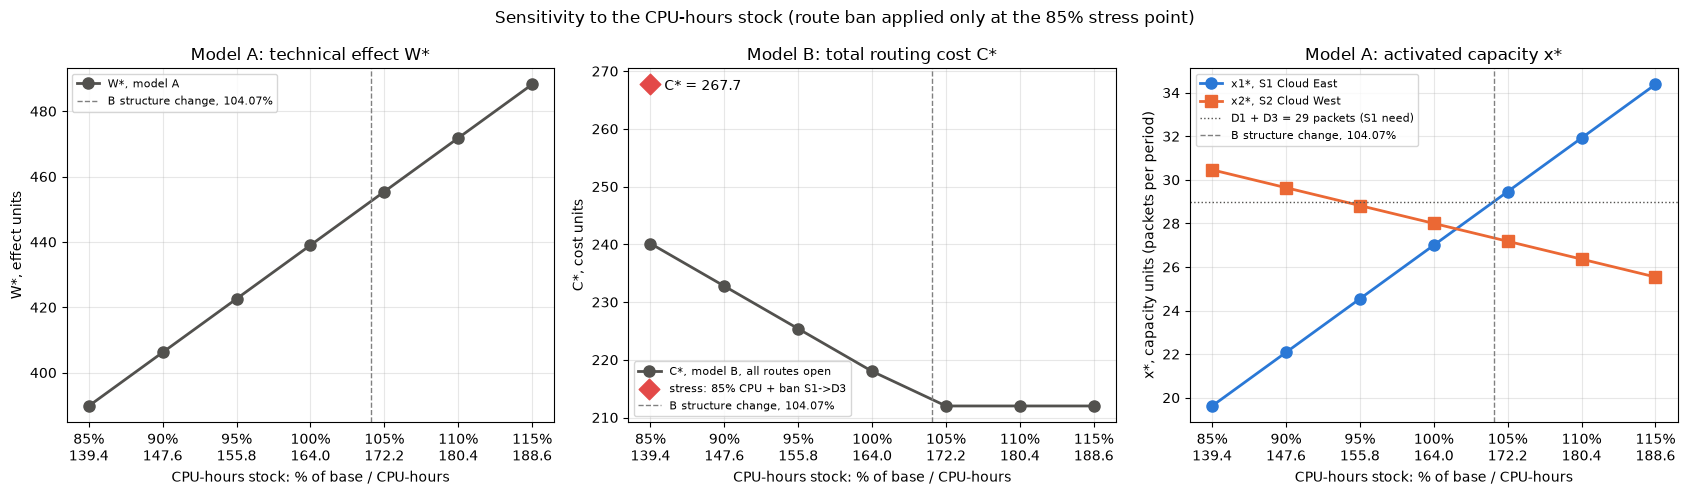

In [28]:
pct = 100 * sweep["CPU factor"]
break_pct = 100 * breakpoint_factor
stress = stress_table.loc["stress: CPU -15% + ban"]

fig, axes = plt.subplots(1, 3, figsize=(17, 5))

ax = axes[0]
ax.plot(pct, sweep["W*"], color=INK, lw=2, marker="o", ms=8, label="W*, model A")
ax.set_ylabel("W*, effect units")
ax.set_title("Model A: technical effect W*")

ax = axes[1]
ax.plot(pct, sweep["C*"], color=INK, lw=2, marker="o", ms=8, label="C*, model B, all routes open")
ax.scatter(100 * STRESS_FACTOR, stress["C*"], s=110, marker="D", color=STRESS_COLOR, zorder=3,
           label="stress: 85% CPU + ban S1->D3")
ax.annotate(f"C* = {stress['C*']:.1f}", (100 * STRESS_FACTOR, stress["C*"]),
            textcoords="offset points", xytext=(10, -4))
ax.set_ylabel("C*, cost units")
ax.set_title("Model B: total routing cost C*")

ax = axes[2]
ax.plot(pct, sweep["x1*"], color=S1_COLOR, lw=2, marker="o", ms=8, label="x1*, S1 Cloud East")
ax.plot(pct, sweep["x2*"], color=S2_COLOR, lw=2, marker="s", ms=8, label="x2*, S2 Cloud West")
ax.axhline(s1_need, color=INK, lw=1, ls=":", label=f"D1 + D3 = {s1_need:.0f} packets (S1 need)")
ax.set_ylabel("x*, capacity units (packets per period)")
ax.set_title("Model A: activated capacity x*")

for ax in axes:
    ax.axvline(break_pct, color="gray", lw=1, ls="--", label=f"B structure change, {break_pct:.2f}%")
    ax.set_xticks(pct)
    ax.set_xticklabels([f"{p:.0f}%\n{p / 100 * RES_STOCK[STRESS_RES]:.1f}" for p in pct])
    ax.set_xlabel("CPU-hours stock: % of base / CPU-hours")
    ax.grid(alpha=0.3)
    ax.legend(fontsize=8)

fig.suptitle("Sensitivity to the CPU-hours stock (route ban applied only at the 85% stress point)")
plt.tight_layout()
plt.show()

- $W^*$ зростає лінійно, на 2 од. ефекту на кожну CPU-годину. У всьому діапазоні базис A не змінюється, активними лишаються CPU і RAM.
- $x_1^*$ зростає, а $x_2^*$ спадає, бо додаткові CPU-години йдуть на S1, а RAM, що лишається вичерпаним, перетікає від S2 до S1. Аналітично $x_1^* = (3b_{CPU} - 222)/10$, $x_2^* = (444 - b_{CPU})/10$, $W^* = 2b_{CPU} + 111$. Структура A зберігається, поки $x_1^*, x_2^* \ge 0$, тобто $74 \le b_{CPU} \le 444$ (45-271 % бази), з великим запасом щодо діапазону 85-115 %.
- $C^*$ спадає на $3 \cdot 0{,}3 = 0{,}9$ грош. од. на CPU-годину (кожна CPU-година дає S1 +0,3 одиниці, а кожна одиниця S1 економить 3), доки $x_1^* < 29$. Після цього $C^*$ виходить на плато 212, бо S1 вистачає на D1 і D3, усі напрями йдуть найдешевшими маршрутами, і додатковий CPU вартість уже не знижує.
- Перша точка зміни на сітці 5 % -- 105 % (172,2 CPU-год), де в B потужність S1 перестає бути активною, і маршрут S2->D3 зникає. Точний поріг -- $x_1^* = 29$ при $b_{CPU} = 512/3 \approx 170{,}67$ CPU-год (104,07 %); бісекція й аналітична формула збігаються.
- У стрес-точці (85 % + заборона) $C^* = 267{,}7$ лежить вище кривої без заборони (240,14). Різниця 27,56 грош. од. -- це ціна недоступності маршруту S1->D3 за скороченого CPU.

## 9. Перевірка, декомпозиція і висновок

### Незалежна перевірка

Код нижче не використовує `res.slack` чи `res.fun` для перевірки обмежень, а перераховує всі нерівності, рівності попиту, невід'ємність і цілі з вхідних даних. Оптимальність перевіряємо перебором усіх базисних розв'язків (вершин) стандартної форми -- методом, що взагалі не залежить від `linprog`. Перевіряються всі розв'язані екземпляри, тобто чотири варіанти стресу і сім точок параметричного аналізу.

In [ ]:
def verify_a(x, stock, W_reported):
    """
    Plain-numpy check of a model A solution.
    """
    used = RES_USE @ x
    return {"x >= 0": bool((x >= -TOL).all()),
            "CPU <= stock": bool(used[0] <= stock[0] + TOL),
            "RAM <= stock": bool(used[1] <= stock[1] + TOL),
            "W = p @ x": bool(np.isclose(EFFECT @ x, W_reported))}


def verify_b(y, capacity, banned, C_reported):
    """
    Plain-numpy check of a model B solution.
    """
    return {**check_flow_plan(y, capacity, banned),
            "C = sum c*y": bool(np.isclose(COST.ravel() @ y, C_reported))}


def vertex_enumeration(c, A_ub, b_ub, A_eq=None, b_eq=None, zero_vars=()):
    """
    Solver-free LP: enumerate basic solutions of the standard form, return (min value, z).
    """
    n, m_ub = len(c), len(b_ub)
    M, rhs = np.hstack([A_ub, np.eye(m_ub)]), np.asarray(b_ub, float)   # [A_ub I][z; s] = b_ub
    if A_eq is not None:
        M = np.vstack([M, np.hstack([A_eq, np.zeros((len(b_eq), m_ub))])])
        rhs = np.concatenate([rhs, b_eq])
    allowed = [k for k in range(n + m_ub) if k not in zero_vars]
    best_val, best_z = np.inf, None
    for basis in itertools.combinations(allowed, M.shape[0]):
        B = M[:, basis]
        if abs(np.linalg.det(B)) < 1e-9:
            continue
        z_basis = np.linalg.solve(B, rhs)
        if (z_basis < -TOL).any():
            continue
        z = np.zeros(n + m_ub)
        z[list(basis)] = z_basis
        if c @ z[:n] < best_val - TOL:
            best_val, best_z = c @ z[:n], z[:n]
    return best_val, best_z


verification_rows = []
for label, factor, banned, ra, rb in stress_solutions + sweep_solutions:
    stock = scaled_stock(factor)
    W_enum, _ = vertex_enumeration(-EFFECT, RES_USE, stock)
    mb = build_model_b(ra.x, banned)
    C_enum, _ = vertex_enumeration(mb["c"], mb["A_ub"], mb["b_ub"], mb["A_eq"], mb["b_eq"],
                                   zero_vars={i * N_DESTS + j for i, j in banned})
    verification_rows.append({
        "instance": label,
        "status A, B = 0": ra.status == 0 and rb.status == 0,
        **verify_a(ra.x, stock, -ra.fun),
        **verify_b(rb.x, ra.x, banned, rb.fun),
        "W* = max over vertices": bool(np.isclose(-ra.fun, -W_enum)),
        "C* = min over vertices": bool(np.isclose(rb.fun, C_enum)),
    })

verification = pd.DataFrame(verification_rows).set_index("instance")
display(verification)
assert verification.all().all()
print("all checks passed:", verification.all().all())

,"status A, B = 0",x >= 0,CPU <= stock,RAM <= stock,W = p @ x,y >= 0,demand (=),capacity (<=),banned = 0,C = sum c*y,W* = max over vertices,C* = min over vertices
instance,,,,,,,,,,,,
base,True,True,True,True,True,True,True,True,True,True,True,True
CPU -15%,True,True,True,True,True,True,True,True,True,True,True,True
ban S1->D3,True,True,True,True,True,True,True,True,True,True,True,True
stress: CPU -15% + ban,True,True,True,True,True,True,True,True,True,True,True,True
sweep 85%,True,True,True,True,True,True,True,True,True,True,True,True
sweep 90%,True,True,True,True,True,True,True,True,True,True,True,True
sweep 95%,True,True,True,True,True,True,True,True,True,True,True,True
sweep 100%,True,True,True,True,True,True,True,True,True,True,True,True
sweep 105%,True,True,True,True,True,True,True,True,True,True,True,True


all checks passed: True


### Прогноз і результат

| Прогноз (розділ 2) | Результат | Оцінка |
|---|---|---|
| Дефіцитний ресурс -- CPU | обидва ресурси вичерпані, $W^*$ зростає на 2 з кожною CPU-годиною | збігся |
| Змішаний план, активні CPU і RAM | $x^* = (27;\ 28)$, обидва запаси 0 | збігся |
| Маршрути S1->D1, S2->D2, S1->D3 | саме вони + вимушені 2 пакети S2->D3 | збігся |
| Потужність > попиту, S1 не вистачить на 29 | 55 > 45; S1 = 27 < 29, на S2 10 одиниць резерву | збігся |
| Скорочення CPU вдарить по S1 | $x_1^*$ -27,3 %, але $x_2^*$ зросло на 8,8 % | частково, не передбачив перетоку RAM до S2 |
| Стрес помітно підвищить $C^*$ | +22,8 %, але стрес дешевший за саму заборону (267,7 < 280) | частково, не передбачив, що скорочення CPU пом'якшить заборону |

### Оцінка декомпозиції A->B

Схема A->B виправдана, якщо:
1. Рішення A приймається заздалегідь і на довший горизонт (резервування, квоти), а маршрутизація -- оперативно.
2. Потужності з запасом покривають попит, включно з вимушеними маршрутами, тобто $x_1^* + x_2^* \ge \sum_j d_j$, і кожен напрям має достатньо потужності на дозволених джерелах.
3. Ефект $p_i$ не залежить від того, яких клієнтів обслуговує потужність.
4. Витрати маршрутизації малі порівняно з цінністю потужності, тож їх можна оптимізувати окремо майже без втрат.

Спільна модель могла б дати інший план, бо A максимізує $W$ і не «бачить» вартостей $c_{ij}$. У базі A обирає $x^* = (27;\ 28)$, і B платить 218 через брак 2 одиниць на S1. План $x = (29;\ 16)$ теж допустимий для A (CPU $4 \cdot 29 + 2 \cdot 16 = 148 \le 164$, RAM $29 + 48 = 77 \le 111$) і дозволяє мінімальну вартість 212, але дає $W = 373 < 439$. Спільна модель, наприклад «мінімізувати $C$ за умови $W \ge W_{min}$» або «максимізувати $W - \lambda C$», могла б обрати саме такий компроміс. У стресі із забороною розрив ще помітніший, бо B потрібно щонайменше 32 одиниці на S2 (D2 + D3), A дає 30,46, а на S1 лишаються 5,08 непотрібних одиниць.

Є й ризик недопустимості, адже A не знає про попит. Якщо запас CPU впаде нижче 114 CPU-год (69,5 % бази), то $x_1^* + x_2^* = (2b_{CPU} + 222)/10 < 45$, і B стане недопустимою, хоча A розв'язується успішно. Спільна модель з рівностями попиту одразу показала б нестачу ресурсу.

### Вибір методу

Обидві моделі -- задачі лінійного програмування з неперервними змінними. Допустима множина опукла, тому будь-який локальний оптимум глобальний, а HiGHS (симплекс) знаходить його точно за мілісекунди.

Жадібне правило швидке й прозоре, але без гарантій. У базі воно випадково оптимальне, у прикладі 2x2 дорожче на 120 %, а в стресі заходить у глухий кут.

Метаевристики (генетичний алгоритм, імітація відпалу, мурашиний алгоритм) доречні для неопуклих, великих комбінаторних або «чорноскринькових» задач, як-от цілочислові сервери з нелінійними витратами, маршрутизація із затримками й чергами. Для цієї ЛП вони були б повільнішими, стохастичними й не гарантували б оптимальності.

### Висновок і рекомендація

| Сценарій | $x^*$ (S1; S2) | $W^*$ | $C^*$ | Активні в A | Вузьке місце в B | Вільна потужність |
|---|---|---|---|---|---|---|
| База | 27; 28 | 439 | 218 | CPU, RAM | S1 | S2: 10 |
| CPU -15 % | 19,62; 30,46 | 389,8 | 240,14 | CPU, RAM | S1 | S2: 5,08 |
| Заборона S1->D3 | 27; 28 | 439 | 280 | CPU, RAM | S2 | S1: 10 |
| Стрес (обидва) | 19,62; 30,46 | 389,8 | 267,7 | CPU, RAM | S2 | S1: 5,08 |

Власнику системи рекомендую активувати на плановий період 27 одиниць потужності на Cloud East і 28 на Cloud West ($W^* = 439$) і маршрутизувати потік так:
- з Cloud East -- корпоративних клієнтів (D1, 13 пакетів) і 14 пакетів партнерських API (D3);
- з Cloud West -- мобільних клієнтів (D2, 16) і решту 2 пакети D3.

Вартість становить 218 грош. од., а 10 одиниць на Cloud West лишаються резервом.

Якщо можна докупити ресурс, варто брати CPU-години, бо в параметричному аналізі кожна з них додає 2 од. ефекту. Додаткові 6,7 CPU-год (до 170,7) ще й знижують вартість маршрутизації до мінімуму 212.

Маршрут Cloud East -> партнерські API критичний, бо його відмова підвищує вартість на 28 % (до 280) і робить вузьким місцем Cloud West. Тому для нього варто мати резервний канал або додаткову потужність на Cloud West.

Рекомендація чинна, поки попит дорівнює базовому (45 пакетів) і відомий наперед, коефіцієнти $a, p, c$ сталі, а запас RAM становить 111 год. Структура плану A не змінюється для $74 \le b_{CPU} \le 444$ CPU-год, а висновок про вузьке місце S1 у B діє лише до 170,7 CPU-год.

Головна межа моделі в тому, що потужність неперервна, тоді як реальні сервери й інстанси неподільні (потрібна цілочислова модель). Крім того, попит детермінований і без пікових навантажень, затримки та SLA не моделюються, а вартості лінійні, без знижок за обсяг.

### Декларація використання ШІ
Генеративний ШІ (Claude, Anthropic) використано для  покращення візуалізацій та графіків, для оформлення таблиць, для покращення читабельності тексту, та коментарів і документацій у коді.
